In [28]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

words = open('names.txt', 'r').read().splitlines()

chars = sorted(list(set(''.join(words))))
char_to_int = {char: idx + 1 for idx, char in enumerate(chars)}
char_to_int['.'] = 0
int_to_char = {idx:char for char,idx in char_to_int.items()}

In [29]:
block_size = 3
x_context, y_outputs = [], []

for w in words[:5]:

    context = [0]* block_size
    for ch in w + '.':
        ix = char_to_int[ch]
        x_context.append(context)
        y_outputs.append(ix)
        context = context[1:] + [ix]

x_context = torch.tensor(x_context) # 3 chars before y (first 3 are .)
y_outputs = torch.tensor(y_outputs)

In [30]:
print(x_context.shape, x_context.dtype, y_outputs.shape, y_outputs.dtype)
# print(x_context[1])
# print(y_outputs[0])

torch.Size([32, 3]) torch.int64 torch.Size([32]) torch.int64


In [31]:
torch.manual_seed(42)
char_embeddings_table = torch.randn((27, 2))
embedded_context = char_embeddings_table[x_context]


In [32]:
# # rebuild x_context: same 5x3 slots, each id replaced by that row of char_embeddings
# print(char_embeddings_table[:3])
# print(embedded_context.shape)
# print('. - ',char_embeddings_table[0])
# print('e - ',char_embeddings_table[5])
#
# print("emb 0: \n", embedded_context[0])  # rows for [0, 0, 0] -> '.' '.' '.'
# print("emb 1: \n", embedded_context[1])  # rows for [0, 0, 5] -> '.' '.' 'e'
#
# print(embedded_context)

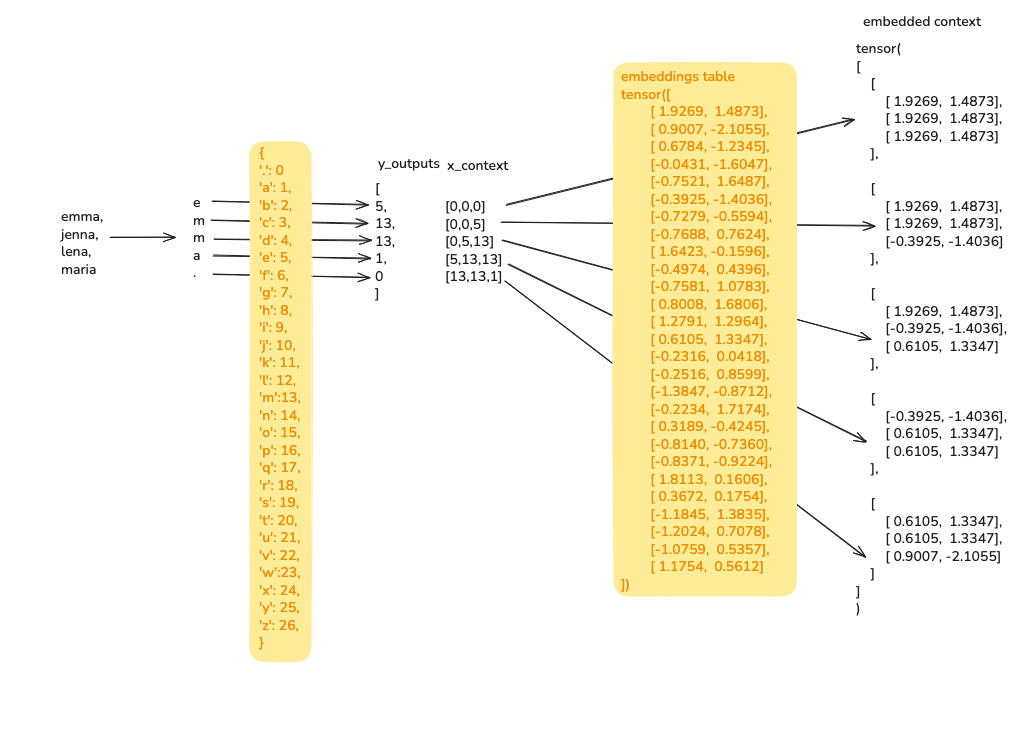

In [33]:
# embedded_context[:,1, :] # from each block take the middle char_embedding

In [34]:
# cat1 = torch.cat((embedded_context[:,0, :],
#                   embedded_context[:,1, :],
#                   embedded_context[:,2, :]), 1)

In [35]:
# cat2 = torch.cat(torch.unbind(embedded_context, 1), 1)
# print(cat2.shape)
# print(cat2[1])

In [36]:
# embedded_context.view(-1, 6) == cat1

In [37]:
# embedded_context.view(-1, 6) == cat2

In [38]:
embedded_context.view(-1, 6)

tensor([[ 1.9269,  1.4873,  1.9269,  1.4873,  1.9269,  1.4873],
        [ 1.9269,  1.4873,  1.9269,  1.4873, -0.3925, -1.4036],
        [ 1.9269,  1.4873, -0.3925, -1.4036,  0.6105,  1.3347],
        [-0.3925, -1.4036,  0.6105,  1.3347,  0.6105,  1.3347],
        [ 0.6105,  1.3347,  0.6105,  1.3347,  0.9007, -2.1055],
        [ 1.9269,  1.4873,  1.9269,  1.4873,  1.9269,  1.4873],
        [ 1.9269,  1.4873,  1.9269,  1.4873, -0.2516,  0.8599],
        [ 1.9269,  1.4873, -0.2516,  0.8599,  1.2791,  1.2964],
        [-0.2516,  0.8599,  1.2791,  1.2964, -0.4974,  0.4396],
        [ 1.2791,  1.2964, -0.4974,  0.4396,  0.3672,  0.1754],
        [-0.4974,  0.4396,  0.3672,  0.1754, -0.4974,  0.4396],
        [ 0.3672,  0.1754, -0.4974,  0.4396,  0.9007, -2.1055],
        [ 1.9269,  1.4873,  1.9269,  1.4873,  1.9269,  1.4873],
        [ 1.9269,  1.4873,  1.9269,  1.4873,  0.9007, -2.1055],
        [ 1.9269,  1.4873,  0.9007, -2.1055,  0.3672,  0.1754],
        [ 0.9007, -2.1055,  0.3672,  0.1

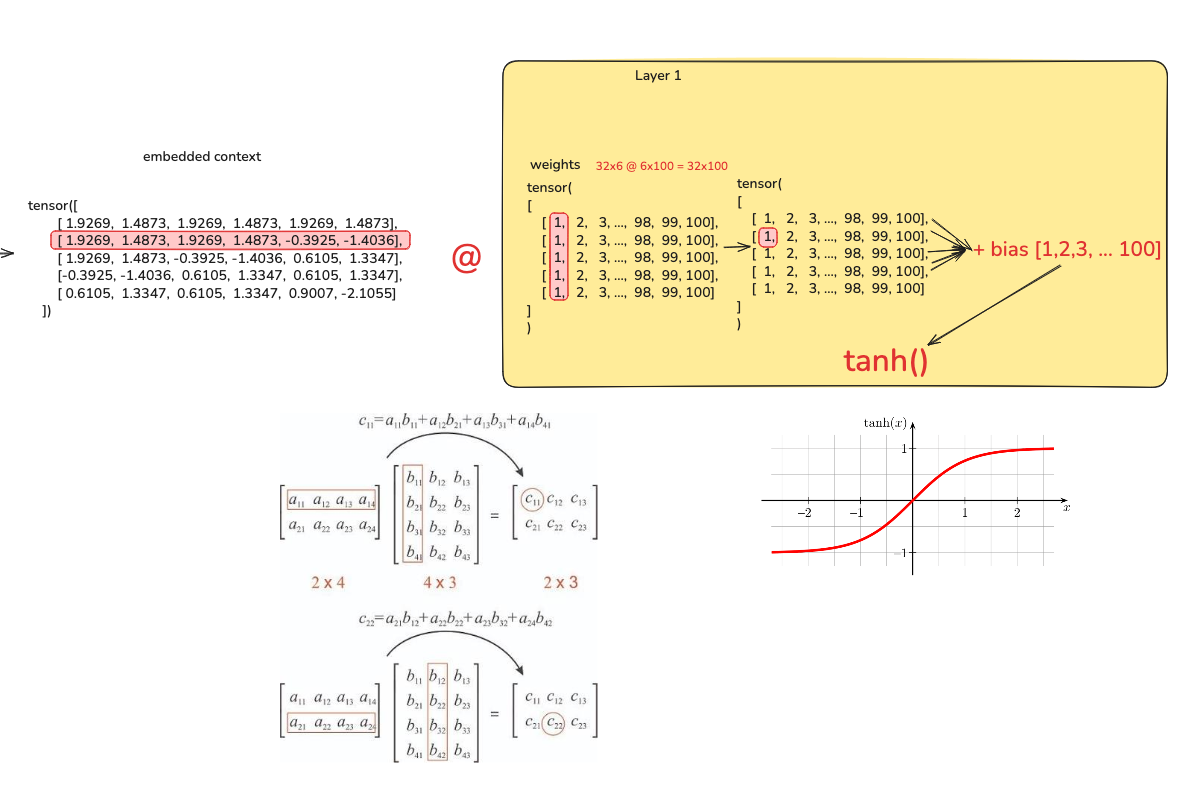

In [39]:
weights1 = torch.randn(6,100)
bias1 = torch.randn(100)
embedded_context.view(-1,6).shape

torch.Size([32, 6])

In [40]:
h = torch.tanh(embedded_context.view(-1,6) @ weights1 + bias1)

In [41]:
h.shape

torch.Size([32, 100])

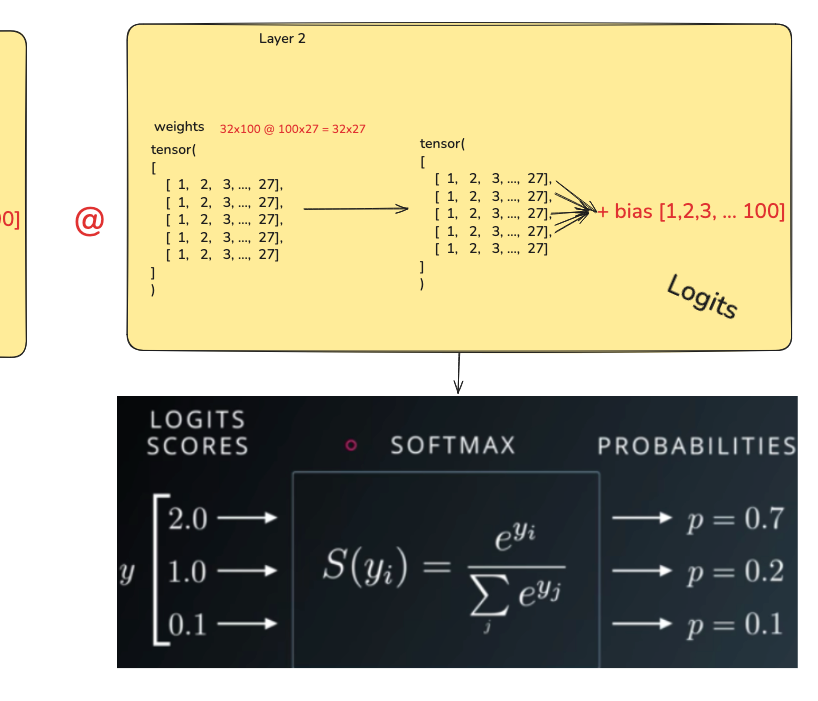

In [42]:
weights2 = torch.randn((100,27))
bias2 = torch.rand(27)

In [43]:
logits = h @ weights2 + bias2
logits.shape

torch.Size([32, 27])

In [44]:
counts = logits.exp()

In [45]:
prob = counts / counts.sum(1, keepdim=True)
prob.shape

torch.Size([32, 27])

In [46]:
prob[torch.arange(len(y_outputs)),y_outputs] # the probability for the correct character - ideally all of this numbers are 1

tensor([8.1857e-06, 5.7391e-07, 1.0762e-10, 2.3411e-12, 3.4035e-13, 7.7950e-11,
        1.8910e-06, 1.7883e-10, 7.9017e-05, 4.3201e-05, 2.2623e-13, 1.8071e-05,
        3.3602e-08, 7.4845e-01, 5.3390e-11, 1.3820e-08, 4.5431e-10, 4.3565e-06,
        6.7772e-08, 1.7510e-03, 1.2679e-12, 2.1085e-03, 7.9733e-08, 5.8411e-10,
        8.4244e-12, 2.4106e-03, 8.6776e-07, 2.1557e-09, 1.0166e-09, 5.3457e-05,
        7.7569e-12, 1.3736e-09])

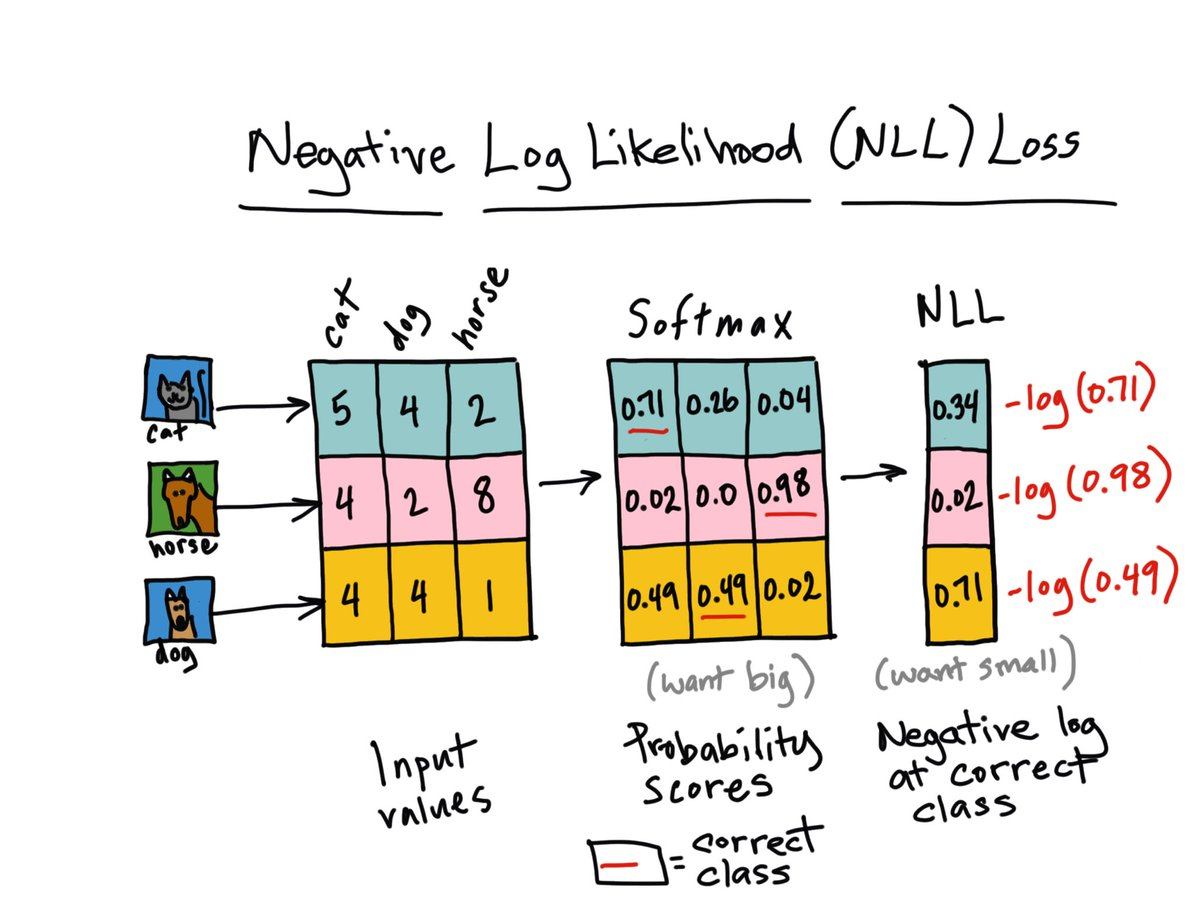

In [47]:
negative_log_likelihood_loss = -(prob[torch.arange(len(y_outputs)),y_outputs]).log().mean()
negative_log_likelihood_loss

tensor(17.2516)

In [48]:
# generator
# embeddings table
# w1 b1 w2 b2
# paramaters pass tanh(@w1+b1) -> @w2+b2 -> logits (log) -> counts (exp) -> prob. -> prob[torch.arange(32), y].log.mean()
# == F.cross.entropy
# params.grad == 0
# loss.backward()
# params.grad = -0.01*params.grad

#ok to achieve softmax

In [49]:
# The softmax function is a mathematical formula that converts a vector of arbitrary real numbers into a valid probability distribution.How It WorksInput: Takes a list of raw numbers (called logits), which can be negative, positive, or zero.Exponentiation: Raises Euler's number (e ﷿﷿﷿ 2.718) to the power of each input value to make all numbers strictly positive.Normalization: Divides each exponentiated value by the sum of all exponentiated values.Output: Produces a new list of values where every number is between 0 and 1, and the entire list adds up to exactly 1.0.

Softmax Function

The softmax function is a mathematical formula that converts a vector of arbitrary real numbers into a valid probability distribution.

How It Works

1. Input
    Takes a list of raw numbers, called logits, which can be negative, positive, or zero.
2. Exponentiation
    Raises Euler﷿﷿﷿s number e \approx 2.718 to the power of each input value, making all numbers strictly positive.
3. Normalization
    Divides each exponentiated value by the sum of all exponentiated values.
4. Output
    Produces a new list of values where:
    * Every value is between 0 and 1.
    * All values add up to exactly 1.0.

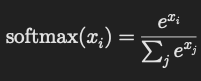

In [50]:
# ok let's do it more clear now
g = torch.Generator().manual_seed(2147483647)
embeddings_table = torch.randn((27,2), generator=g)
weights1 = torch.randn((6,100), generator=g)
bias1 = torch.randn(100, generator=g)
weights2 = torch.randn((100,27), generator=g)
bias2 = torch.randn(27, generator=g)
parameters = [embeddings_table, weights1, bias1, weights2, bias2]

In [51]:
sum(p.nelement() for p in parameters)

3481

In [52]:
for p in parameters:
    p.requires_grad = True

In [1]:
# x_embedded = embeddings_table[x_context]
# h = torch.tanh((x_embedded.view(-1, 6) @ weights1 + bias1))
# logits = h @ weights2 + bias2
# # counts = logits.exp()
# # prob = counts / counts.sum(1, keepdim=True)
# # loss = -prob[torch.arange(32),y_outputs].log().mean()
# loss = F.cross_entropy(logits, y_outputs)

In [54]:
for _ in range(1000):
    #forward pass
    emb = embeddings_table[x_context] #(32,3,2)
    h = torch.tanh(emb.view(-1,6)@weights1+bias1) #(32, 100)
    logits = h @ weights2 + bias2 #(32, 27)
    loss = F.cross_entropy(logits, y_outputs)

    #backward pass
    for p in parameters:
        p.grad = None

    loss.backward()

    #update
    for p in parameters:
        p.data += -0.1*p.grad

print(loss.item())

0.2561384439468384


In [56]:
logits.shape

torch.Size([32, 27])

In [60]:
logits.max(1) # this returns the max out of every array and its index

torch.return_types.max(
values=tensor([13.3348, 17.7905, 20.6013, 20.6120, 16.7355, 13.3348, 15.9984, 14.1723,
        15.9146, 18.3614, 15.9396, 20.9265, 13.3348, 17.1089, 17.1319, 20.0601,
        13.3348, 16.5892, 15.1017, 17.0581, 18.5861, 15.9670, 10.8740, 10.6871,
        15.5056, 13.3348, 16.1794, 16.9743, 12.7426, 16.2008, 19.0846, 16.0195],
       grad_fn=<MaxBackward0>),
indices=tensor([19, 13, 13,  1,  0, 19, 12,  9, 22,  9,  1,  0, 19, 22,  1,  0, 19, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0]))

In [61]:
y_outputs

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [ ]:
# So how you see the overfit is not perfect, but it's close

![image.png](attachment:3b3d4cb6-6214-4e68-8044-cab66b5d8a39.png)